# Common cohort (N=110) — model interpretation

This notebook interprets five selected common-cohort model families on the common 110-patient cohort (43 oligo, 67 poly). Families were selected previously by mean inner-CV macro-F1. Fresh five-fold searches determine interpretation-only hyperparameters, followed by full-cohort refits. Their training or tuning scores are **not new unbiased performance estimates**. The original nested-CV predictions and metrics remain unchanged.

Clinical+transcriptomics and mutation+transcriptomics remain performance-only; their final interpretation membership and SHAP are not computed.

This notebook provides secondary interpretation. The main common-cohort question is whether predictive performance differs across modalities on the same 110 patients and identical frozen outer folds, as reported in the model-results summary. Feature overlap is exploratory and is not a requirement for a fair performance comparison.


In [1]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display

from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/OligoPolyThesis').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.OligoPolyThesis.utils_ml_oligopoly import _primary110_interpretation_LOCKED as LOCKED, load_locked_inputs, fit_interpretation
BASE = Path('/mnt/data3/MCPP-Breast')
OUTPUT = BASE / 'Machine-Learning-Models-poly_vs_oligo/Common-Cohort-Modality-Comparison/primary_110/interpretation'
RANDOM_STATE = 42
N_JOBS = 4
blocks, cohort, source_paths, selected_families = load_locked_inputs(BASE, ROOT)
thesis_display(selected_families.loc[selected_families.configuration.isin(LOCKED), ['configuration', 'family', 'N']])
thesis_display(cohort.groupby('y_true').size().rename('N').rename_axis('baseline_polymetastatic').reset_index())
from scripts.OligoPolyThesis.utils_ml_oligopoly import plot_saved_shap_bar
from scripts.OligoPolyThesis.utils_ml_oligopoly import display_interpretation, display_multimodal_interpretation
from scripts.OligoPolyThesis.utils_ml_oligopoly import (
    symbol_only_saved_plot,
    gene_symbols,
)


,configuration,family,N
0,clinical,logreg_l2,110
1,mutation,random_forest,110
2,transcriptomics,random_forest,110
3,clinical_mutation,random_forest,110
6,clinical_mutation_transcriptomics,random_forest,110


,baseline_polymetastatic,N
0,0,43
1,1,67


## Full-cohort tuning protocol

Only the locked family is searched for each input, using its unchanged compact grid. Five-fold stratified CV uses shuffle=True, seed 42 and macro-F1. Every modality’s learned preprocessing, supervised selection and scaling is fitted on the appropriate inner-training data. Preprocessing caches are keyed on the exact training inputs and labels. No whole-cohort transformed matrix is supplied to inner CV. The final complete pipeline is refitted on all 110 patients only after selecting its parameters.

Mutual information retains seed 42. Passthrough selection remains permitted for mutation and clinical+mutation; all TPM-containing inputs require F200, F500 or MI200. Clinical uses no supervised selector. Estimators remain single-threaded; four workers evaluate candidates.

Completed bundles are loaded only if fingerprints and artifact hashes match. Existing outputs are never silently replaced. Full fitted pipelines and caches remain private; no patient-level SHAP matrix is exported.

## Clinical L2 coefficients

All retained inputs, including one-hot indicators, are standardized. `exp(beta)` describes one fitted-scaler-SD change, not a simple category-reference odds ratio. Raw-unit effects are reported for age at **primary diagnosis**, per year. Category A→B contrasts use beta_B/scale_B − beta_A/scale_A, with other source variables held fixed. No inferential confidence intervals are estimated. Absolute coefficient ranks are predictive, not causal or independent clinical effects.

In [2]:
clinical_dir = fit_interpretation('clinical', blocks, cohort, source_paths, OUTPUT, ROOT, n_jobs=N_JOBS)
thesis_display(pd.DataFrame([json.loads((clinical_dir / 'best_params.json').read_text())]))
thesis_display(pd.read_csv(clinical_dir / 'classifier_input_features.csv').groupby('modality').size().rename('Classifier inputs').to_frame())

START clinical: 10 candidates x 5 folds; 2026-09-24T13:27:7.191+00:00


COMPLETE clinical: 72 classifier inputs; 2026-09-24T13:27:9.491+00:00


,configuration,family,best_params,best_inner_macro_f1,interpretation_only,N,n_splits,scoring,random_state,n_retained_before_selection,n_classifier_inputs,candidate_count
0,clinical,logreg_l2,"{'classifier__C': 10, 'classifier__class_weigh...",0.513,True,110,5,f1_macro,42,72,72,10


,Classifier inputs
modality,
clinical,72


,original_clinical_variable,encoded_level,scaler_SD,standardized_coefficient,odds_multiplier_per_scaler_SD,raw_unit_coefficient,raw_unit_odds_multiplier,direction,absolute_standardized_coefficient_rank
0,abc_smoker,4.000,0.498,-3.200,0.041,NaN,NaN,toward oligo,1
1,abc_grade,3.000,0.472,2.775,16.038,NaN,NaN,toward poly,2
2,abc_lnd_n_positive,9.000,0.134,2.734,15.393,NaN,NaN,toward poly,3
3,abc_multicentric,1.000,0.343,2.408,11.114,NaN,NaN,toward poly,4
4,abc_smoker,2.000,0.134,-2.182,0.113,NaN,NaN,toward oligo,5
5,luminal_b,1.000,0.495,-2.157,0.116,NaN,NaN,toward oligo,6
6,abc_lnd_n_positive,6.000,0.187,2.047,7.744,NaN,NaN,toward poly,7
7,abc_lnd_n_positive,2.000,0.323,2.027,7.593,NaN,NaN,toward poly,8
8,abc_alcohol,5.000,0.486,-1.958,0.141,NaN,NaN,toward oligo,9
9,abc_alcohol,1.000,0.445,-1.855,0.156,NaN,NaN,toward oligo,10


,original_clinical_variable,reference_level,comparison_level,log_odds_contrast,odds_multiplier,interpretation
0,abc_smoker,1.000,2.000,-16.234,0.000,"fitted category A to B, other source variables..."
1,abc_smoker,1.000,3.000,-6.338,0.002,"fitted category A to B, other source variables..."
2,abc_smoker,1.000,4.000,-6.332,0.002,"fitted category A to B, other source variables..."
3,abc_smoker,2.000,3.000,9.896,19852.129,"fitted category A to B, other source variables..."
4,abc_smoker,2.000,4.000,9.902,19966.783,"fitted category A to B, other source variables..."
...,...,...,...,...,...,...
245,abc_ajcc_x_n,19.000,N1,5.576,264.040,"fitted category A to B, other source variables..."
246,abc_ajcc_x_n,19.000,N2plus,4.827,124.884,"fitted category A to B, other source variables..."
247,abc_ajcc_x_n,N0,N1,-0.594,0.552,"fitted category A to B, other source variables..."
248,abc_ajcc_x_n,N0,N2plus,-1.343,0.261,"fitted category A to B, other source variables..."


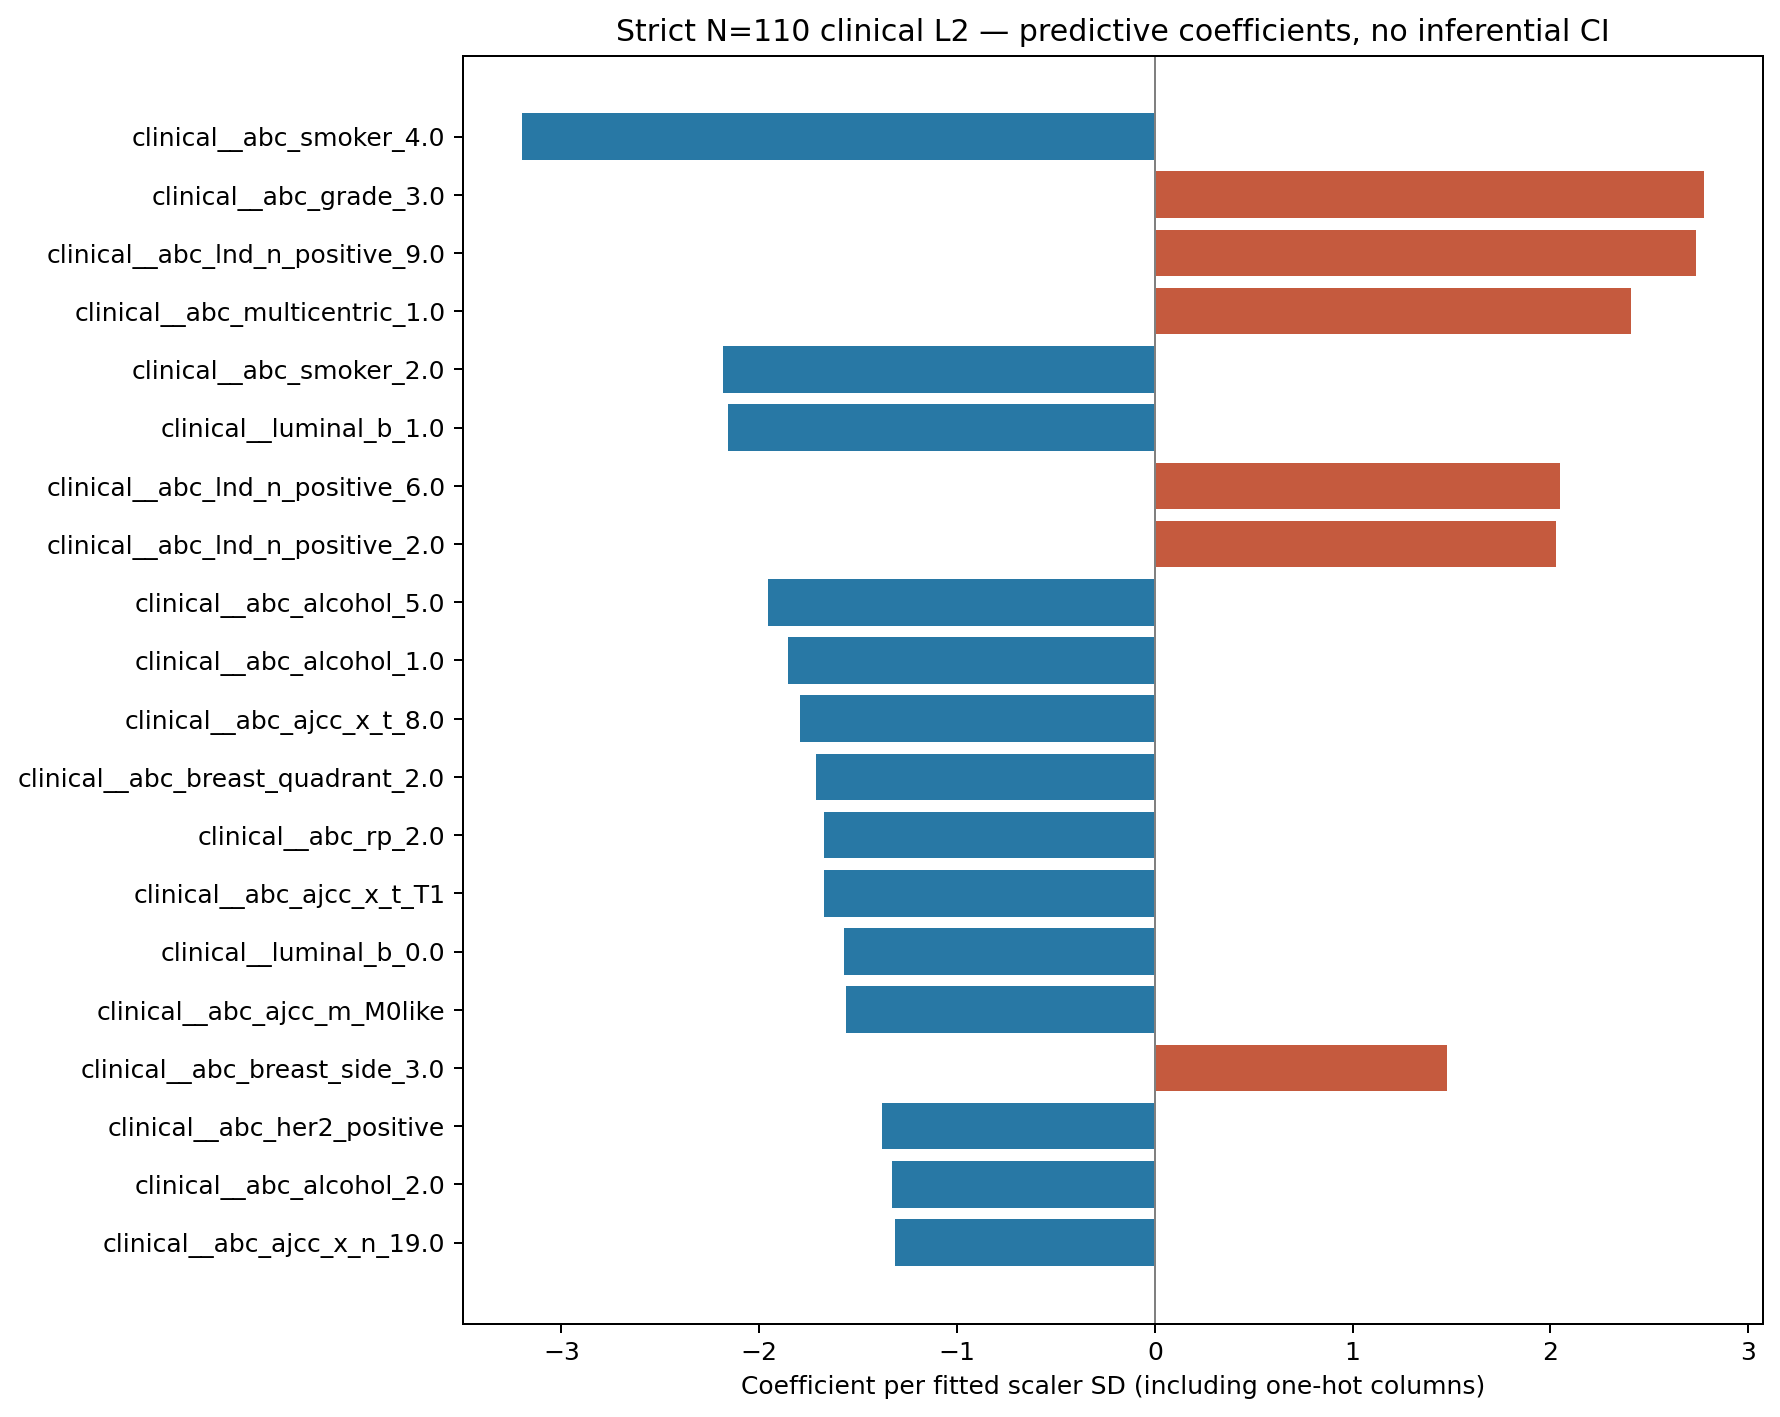

In [3]:
clinical_coefficients = pd.read_csv(clinical_dir / 'clinical_coefficients.csv')
thesis_display(clinical_coefficients[['original_clinical_variable','encoded_level','scaler_SD','standardized_coefficient','odds_multiplier_per_scaler_SD','raw_unit_coefficient','raw_unit_odds_multiplier','direction','absolute_standardized_coefficient_rank']].head(20))
thesis_display(pd.read_csv(clinical_dir / 'clinical_category_contrasts.csv'))
thesis_display(Image(filename=str(clinical_dir / 'clinical_coefficients.png')))

## Mutation Random Forest

Features are binary gene-level mutation-presence indicators, including the established identifier aggregation. They are not mutation burden, allele fractions or verified functional disruptions. SHAP describes the fitted model rather than validated biomarkers; native impurity importance is supplementary.

In [4]:
mutation_dir = fit_interpretation('mutation', blocks, cohort, source_paths, OUTPUT, ROOT, n_jobs=N_JOBS)
thesis_display(pd.DataFrame([json.loads((mutation_dir / 'best_params.json').read_text())]))
thesis_display(pd.read_csv(mutation_dir / 'classifier_input_features.csv').groupby('modality').size().rename('Classifier inputs').to_frame())

START mutation: 128 candidates x 5 folds; 2026-09-24T13:27:9.580+00:00


COMPLETE mutation: 4503 classifier inputs; 2026-09-24T13:27:48.058+00:00


,configuration,family,best_params,best_inner_macro_f1,interpretation_only,N,n_splits,scoring,random_state,n_retained_before_selection,n_classifier_inputs,candidate_count
0,mutation,random_forest,"{'classifier__class_weight': 'balanced', 'clas...",0.574,True,110,5,f1_macro,42,4503,4503,128


,Classifier inputs
modality,
mutation,4503


### Probability-scale TreeSHAP checks

All four RF analyses use interventional TreeExplainer for P(poly=1), with all 110 transformed patient rows as the empirical background and no implicit subsampling. Positive-class mapping, feature ordering, reload probabilities and SHAP additivity are checked before publication. The additivity tolerance is 10⁻⁶ probability units; pipeline-versus-classifier agreement tolerance is 10⁻¹². Reloaded probabilities must be identical.

Beeswarm colors describe the fitted classifier input; continuous genes and binary indicators have been scaled by the pipeline. SHAP signs describe contributions relative to the model’s empirical background prediction. Interventional masking of correlated predictors is not a causal intervention; attribution can redistribute among correlated inputs.

,rank,feature,mean_abs_shap,mean_signed_shap
0,1,MUC4,0.0100,-0.000
1,2,GSE1,0.0040,0.000
2,3,PPP1R15A,0.0039,0.000
3,4,APOLTP,0.0038,0.000
4,5,RALGDS,0.0037,0.000
5,6,MEGF9,0.0037,0.000
6,7,VWF,0.0034,-0.000
7,8,PLA2R1,0.0033,0.000
8,9,C10orf90,0.0031,-0.000
9,10,PLB1,0.0027,0.000


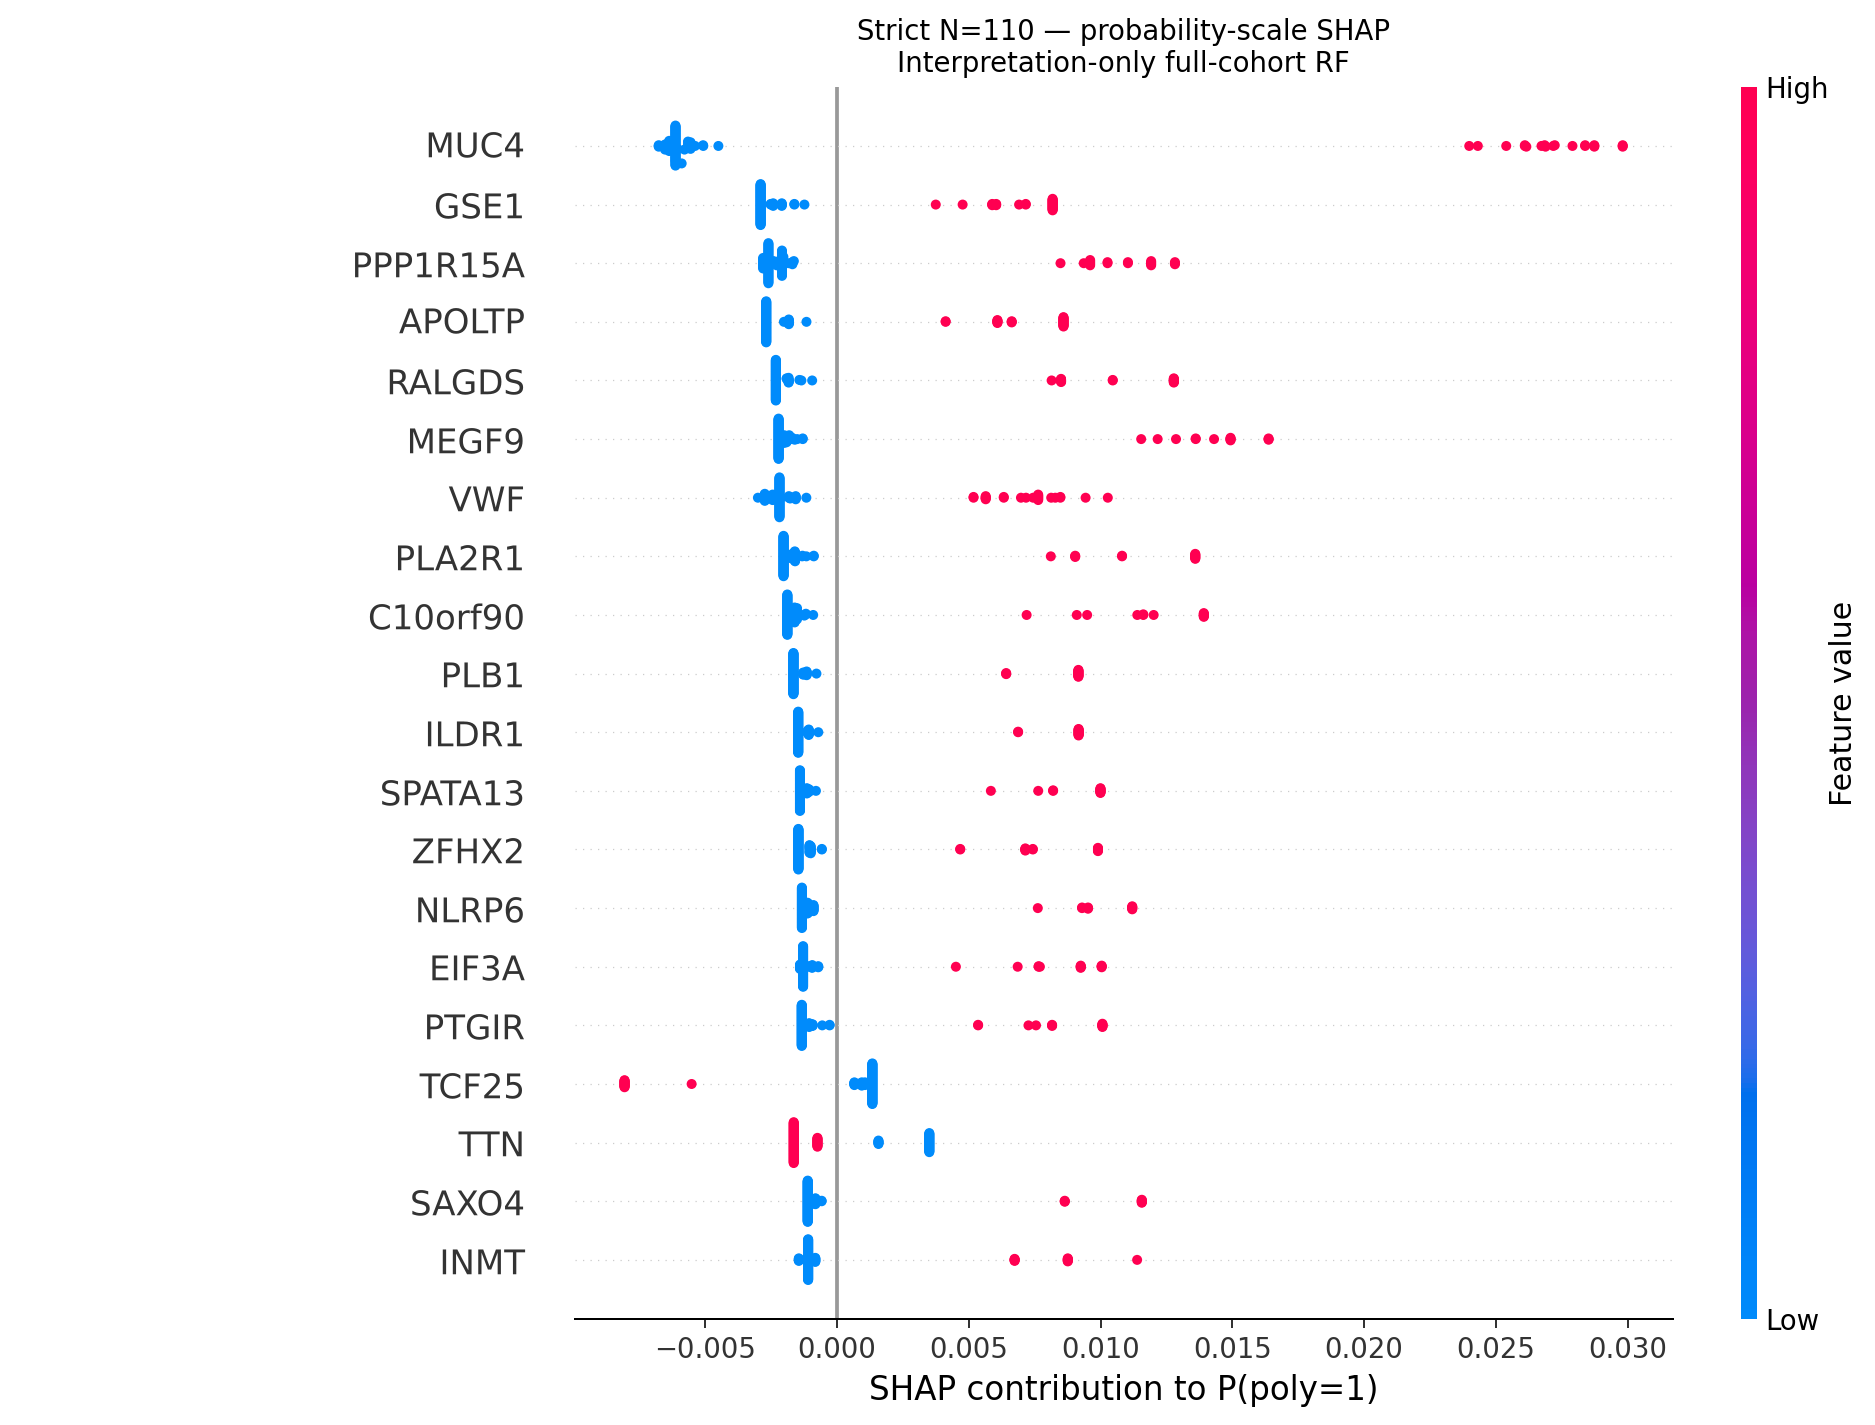

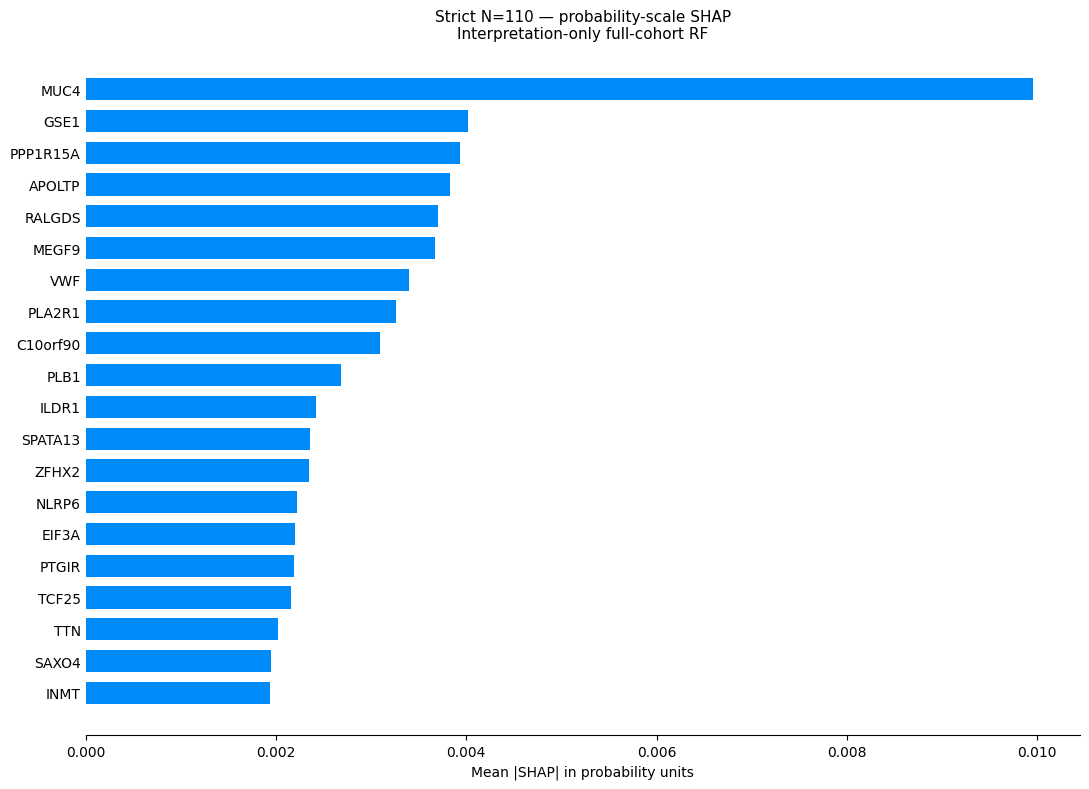

,feature_position,feature,original_clinical_variable,encoded_level,native_impurity_importance,native_rank
0,4499,MUC4,NaN,NaN,0.0402,1
1,4252,MEGF9,NaN,NaN,0.0185,2
2,2447,RALGDS,NaN,NaN,0.0169,3
3,2287,C10orf90,NaN,NaN,0.0146,4
4,1516,GSE1,NaN,NaN,0.0143,5
5,496,PPP1R15A,NaN,NaN,0.0140,6
6,2410,CACHD1,NaN,NaN,0.0138,7
7,3628,APOLTP,NaN,NaN,0.0134,8
8,3374,SPATA13,NaN,NaN,0.0130,9
9,2036,ILDR1,NaN,NaN,0.0130,10


,model_output,positive_class,positive_class_index,feature_perturbation,background_N,RF_output_shape,positive_class_SHAP_shape,base_value,max_absolute_additivity_error,mean_absolute_additivity_error,absolute_tolerance,feature_names_order_validated,background_subsampled
0,P(poly=1),1,1,interventional,110,"[110, 4503, 2]","[110, 4503]",0.510,1.23e-8,3.43e-9,1.00e-6,True,False


In [5]:
display_interpretation(pd.read_csv(mutation_dir / 'shap_ranking.csv')[['rank','display_name','feature','modality','mean_abs_shap','mean_signed_shap']].head(20))
display_interpretation(symbol_only_saved_plot(mutation_dir / 'shap_beeswarm.png'))
plot_saved_shap_bar(mutation_dir / 'shap_ranking.csv')
plt.show()
display_interpretation(pd.read_csv(mutation_dir / 'native_importance.csv').head(20))
display_interpretation(pd.DataFrame([json.loads((mutation_dir / 'shap_agreement.json').read_text())]))

## Transcriptomics Random Forest

SHAP ranks the genes actually passed to the fitted RF after fold-local tuning. Gene symbols come from the preserved gene-symbol mapping; unmapped identifiers remain explicit. None of the eight biological-characterization genes is forced into the selector.

In [6]:
transcriptomics_dir = fit_interpretation('transcriptomics', blocks, cohort, source_paths, OUTPUT, ROOT, n_jobs=N_JOBS)
thesis_display(pd.DataFrame([json.loads((transcriptomics_dir / 'best_params.json').read_text())]))
thesis_display(pd.read_csv(transcriptomics_dir / 'classifier_input_features.csv').groupby('modality').size().rename('Classifier inputs').to_frame())

START transcriptomics: 96 candidates x 5 folds; 2026-09-24T13:27:48.199+00:00


COMPLETE transcriptomics: 200 classifier inputs; 2026-09-24T13:29:2.294+00:00


,configuration,family,best_params,best_inner_macro_f1,interpretation_only,N,n_splits,scoring,random_state,n_retained_before_selection,n_classifier_inputs,candidate_count
0,transcriptomics,random_forest,"{'classifier__class_weight': 'balanced', 'clas...",0.653,True,110,5,f1_macro,42,18122,200,96


,Classifier inputs
modality,
transcriptomics,200


,rank,feature,mean_abs_shap,mean_signed_shap
0,1,SLC5A8,0.0472,0.000
1,2,H3C14,0.0353,-0.000
2,3,YARS2,0.0176,-0.000
3,4,KIAA2012,0.0166,0.000
4,5,ACSL6,0.0148,-0.000
5,6,MYEOV,0.0135,0.000
6,7,NRGN,0.0105,0.000
7,8,TTLL3,0.0100,0.000
8,9,TMPRSS4,0.0099,0.000
9,10,TP53AIP1,0.0096,-0.000


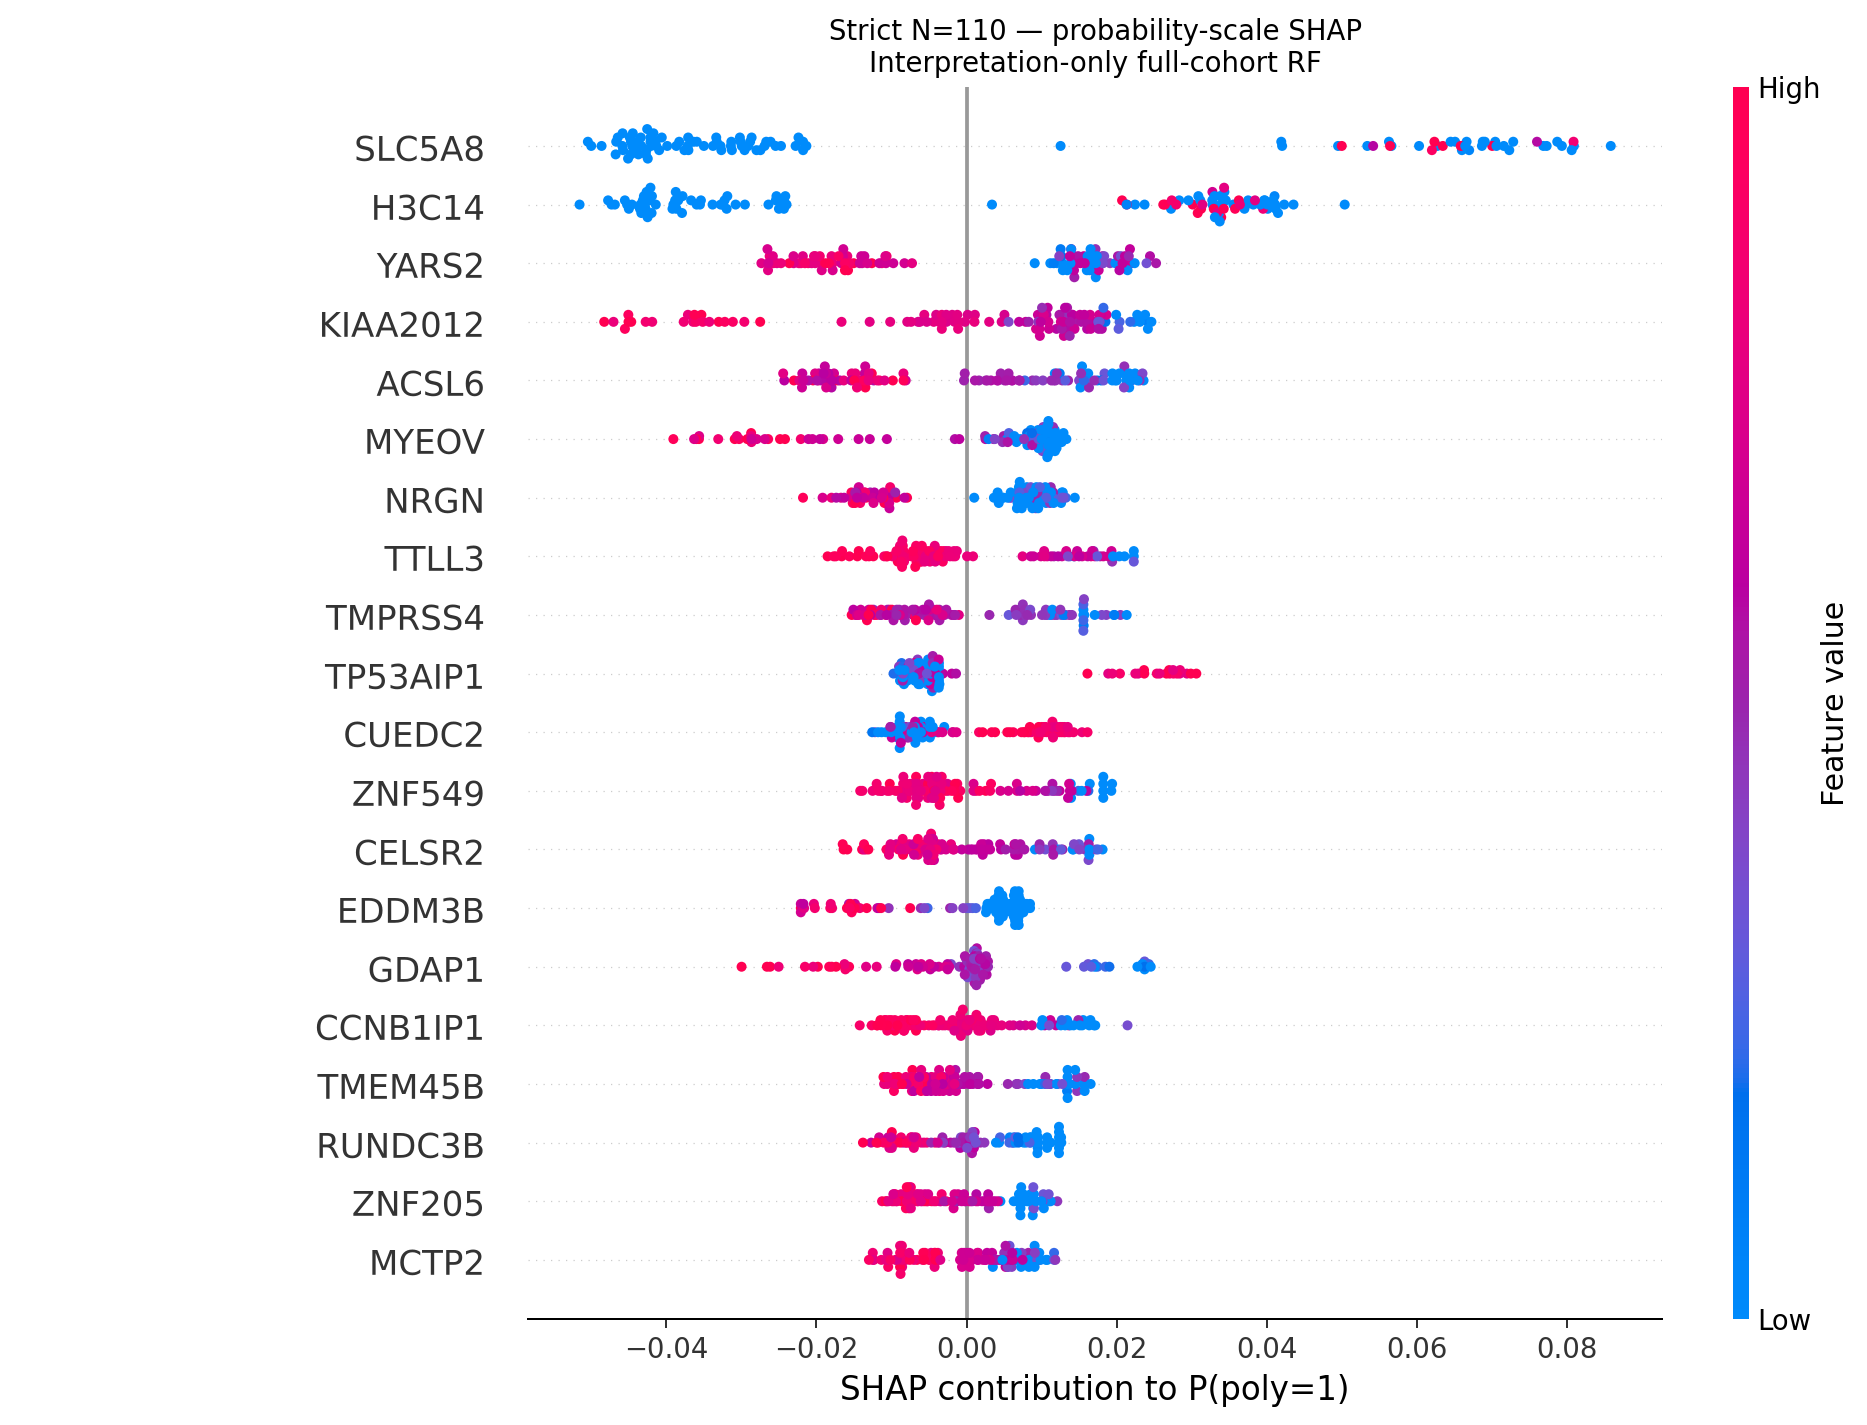

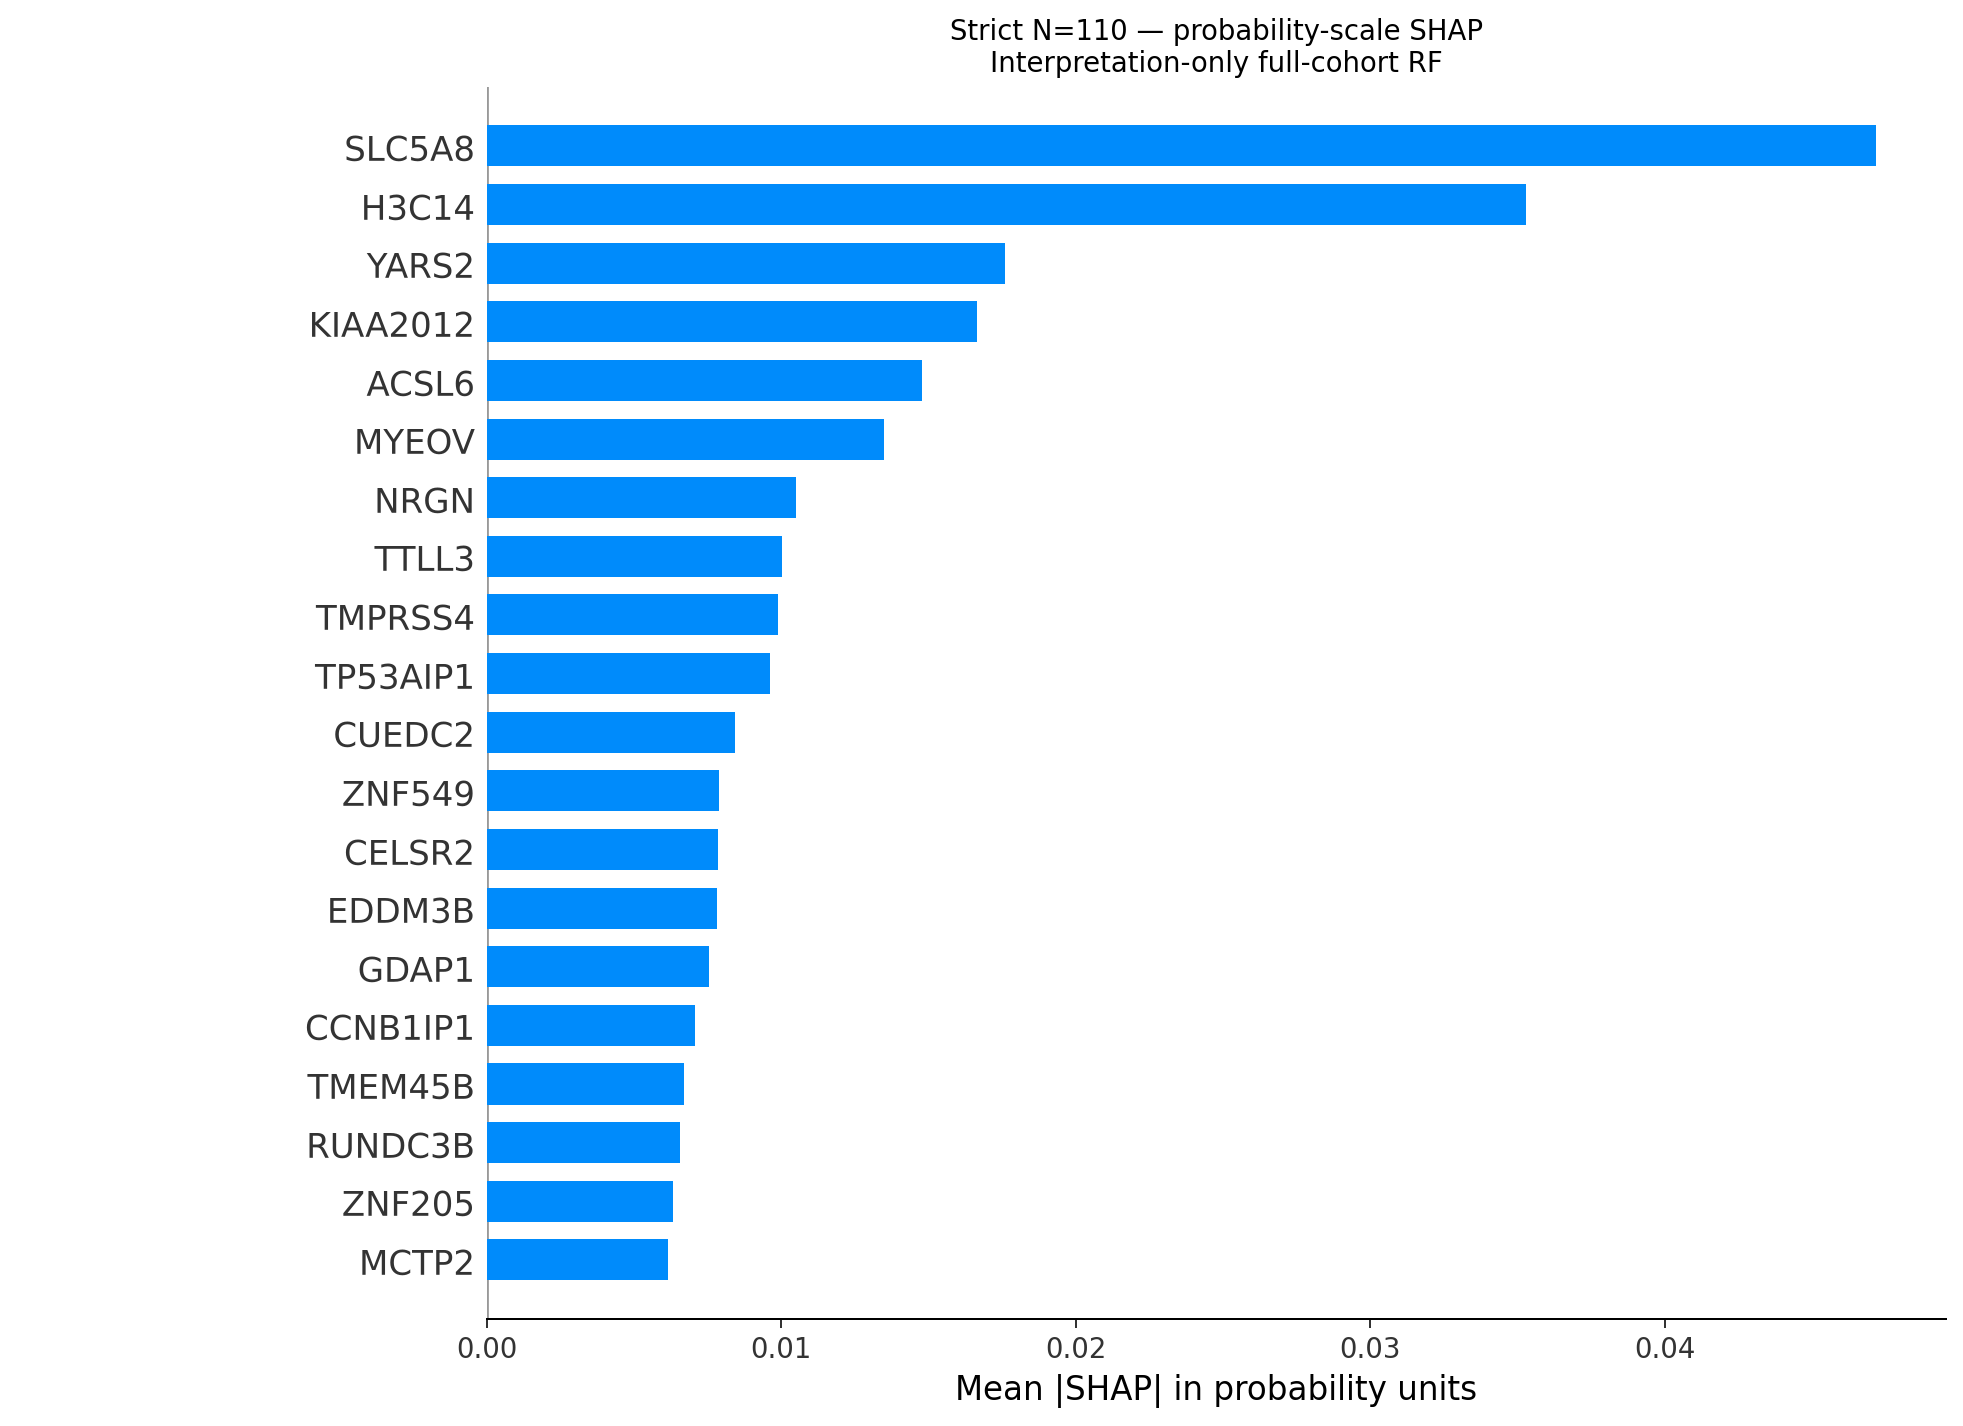

,feature_position,feature,original_clinical_variable,encoded_level,native_impurity_importance,native_rank
0,195,SLC5A8,NaN,NaN,0.0788,1
1,182,H3C14,NaN,NaN,0.0621,2
2,165,KIAA2012,NaN,NaN,0.0406,3
3,147,MYEOV,NaN,NaN,0.0305,4
4,80,YARS2,NaN,NaN,0.0299,5
5,133,ACSL6,NaN,NaN,0.0274,6
6,34,GDAP1,NaN,NaN,0.0271,7
7,188,TTLL3,NaN,NaN,0.0236,8
8,52,TP53AIP1,NaN,NaN,0.0216,9
9,115,NRGN,NaN,NaN,0.0215,10


,model_output,positive_class,positive_class_index,feature_perturbation,background_N,RF_output_shape,positive_class_SHAP_shape,base_value,max_absolute_additivity_error,mean_absolute_additivity_error,absolute_tolerance,feature_names_order_validated,background_subsampled
0,P(poly=1),1,1,interventional,110,"[110, 200, 2]","[110, 200]",0.562,7.18e-9,3.49e-9,1.00e-6,True,False


In [7]:
display_interpretation(pd.read_csv(transcriptomics_dir / 'shap_ranking.csv')[['rank','display_name','feature','modality','mean_abs_shap','mean_signed_shap']].head(20))
display_interpretation(symbol_only_saved_plot(transcriptomics_dir / 'shap_beeswarm.png'))
display_interpretation(symbol_only_saved_plot(transcriptomics_dir / 'shap_bar.png'))
display_interpretation(pd.read_csv(transcriptomics_dir / 'native_importance.csv').head(20))
display_interpretation(pd.DataFrame([json.loads((transcriptomics_dir / 'shap_agreement.json').read_text())]))

## Clinical + mutation Random Forest

Clinical encoded inputs and mutation indicators retain modality prefixes. The final selector may choose a reduced set or passthrough. Passthrough membership is retention, not supervised selection or importance.

In [8]:
clinical_mutation_dir = fit_interpretation('clinical_mutation', blocks, cohort, source_paths, OUTPUT, ROOT, n_jobs=N_JOBS)
thesis_display(pd.DataFrame([json.loads((clinical_mutation_dir / 'best_params.json').read_text())]))
thesis_display(pd.read_csv(clinical_mutation_dir / 'classifier_input_features.csv').groupby('modality').size().rename('Classifier inputs').to_frame())

START clinical_mutation: 128 candidates x 5 folds; 2026-09-24T13:29:2.450+00:00


COMPLETE clinical_mutation: 200 classifier inputs; 2026-09-24T13:29:45.310+00:00


,configuration,family,best_params,best_inner_macro_f1,interpretation_only,N,n_splits,scoring,random_state,n_retained_before_selection,n_classifier_inputs,candidate_count
0,clinical_mutation,random_forest,"{'classifier__class_weight': 'balanced', 'clas...",0.636,True,110,5,f1_macro,42,4575,200,128


,Classifier inputs
modality,
clinical,5
mutation,195


,rank,feature,modality,mean_abs_shap,mean_signed_shap
0,1,PLB1,mutation,0.0112,0.000
1,2,BOC,mutation,0.0075,0.000
2,3,ZNF83,mutation,0.0072,0.000
3,4,CEP290,mutation,0.0064,-0.000
4,5,CCDC9,mutation,0.0062,-0.000
5,6,FSIP2,mutation,0.0056,-0.000
6,7,TCF25,mutation,0.0050,-0.000
7,8,NWD1,mutation,0.0046,-0.000
8,9,ATG2A,mutation,0.0044,-0.000
9,10,clinical__abc_multifocal_1.0,clinical,0.0039,0.000


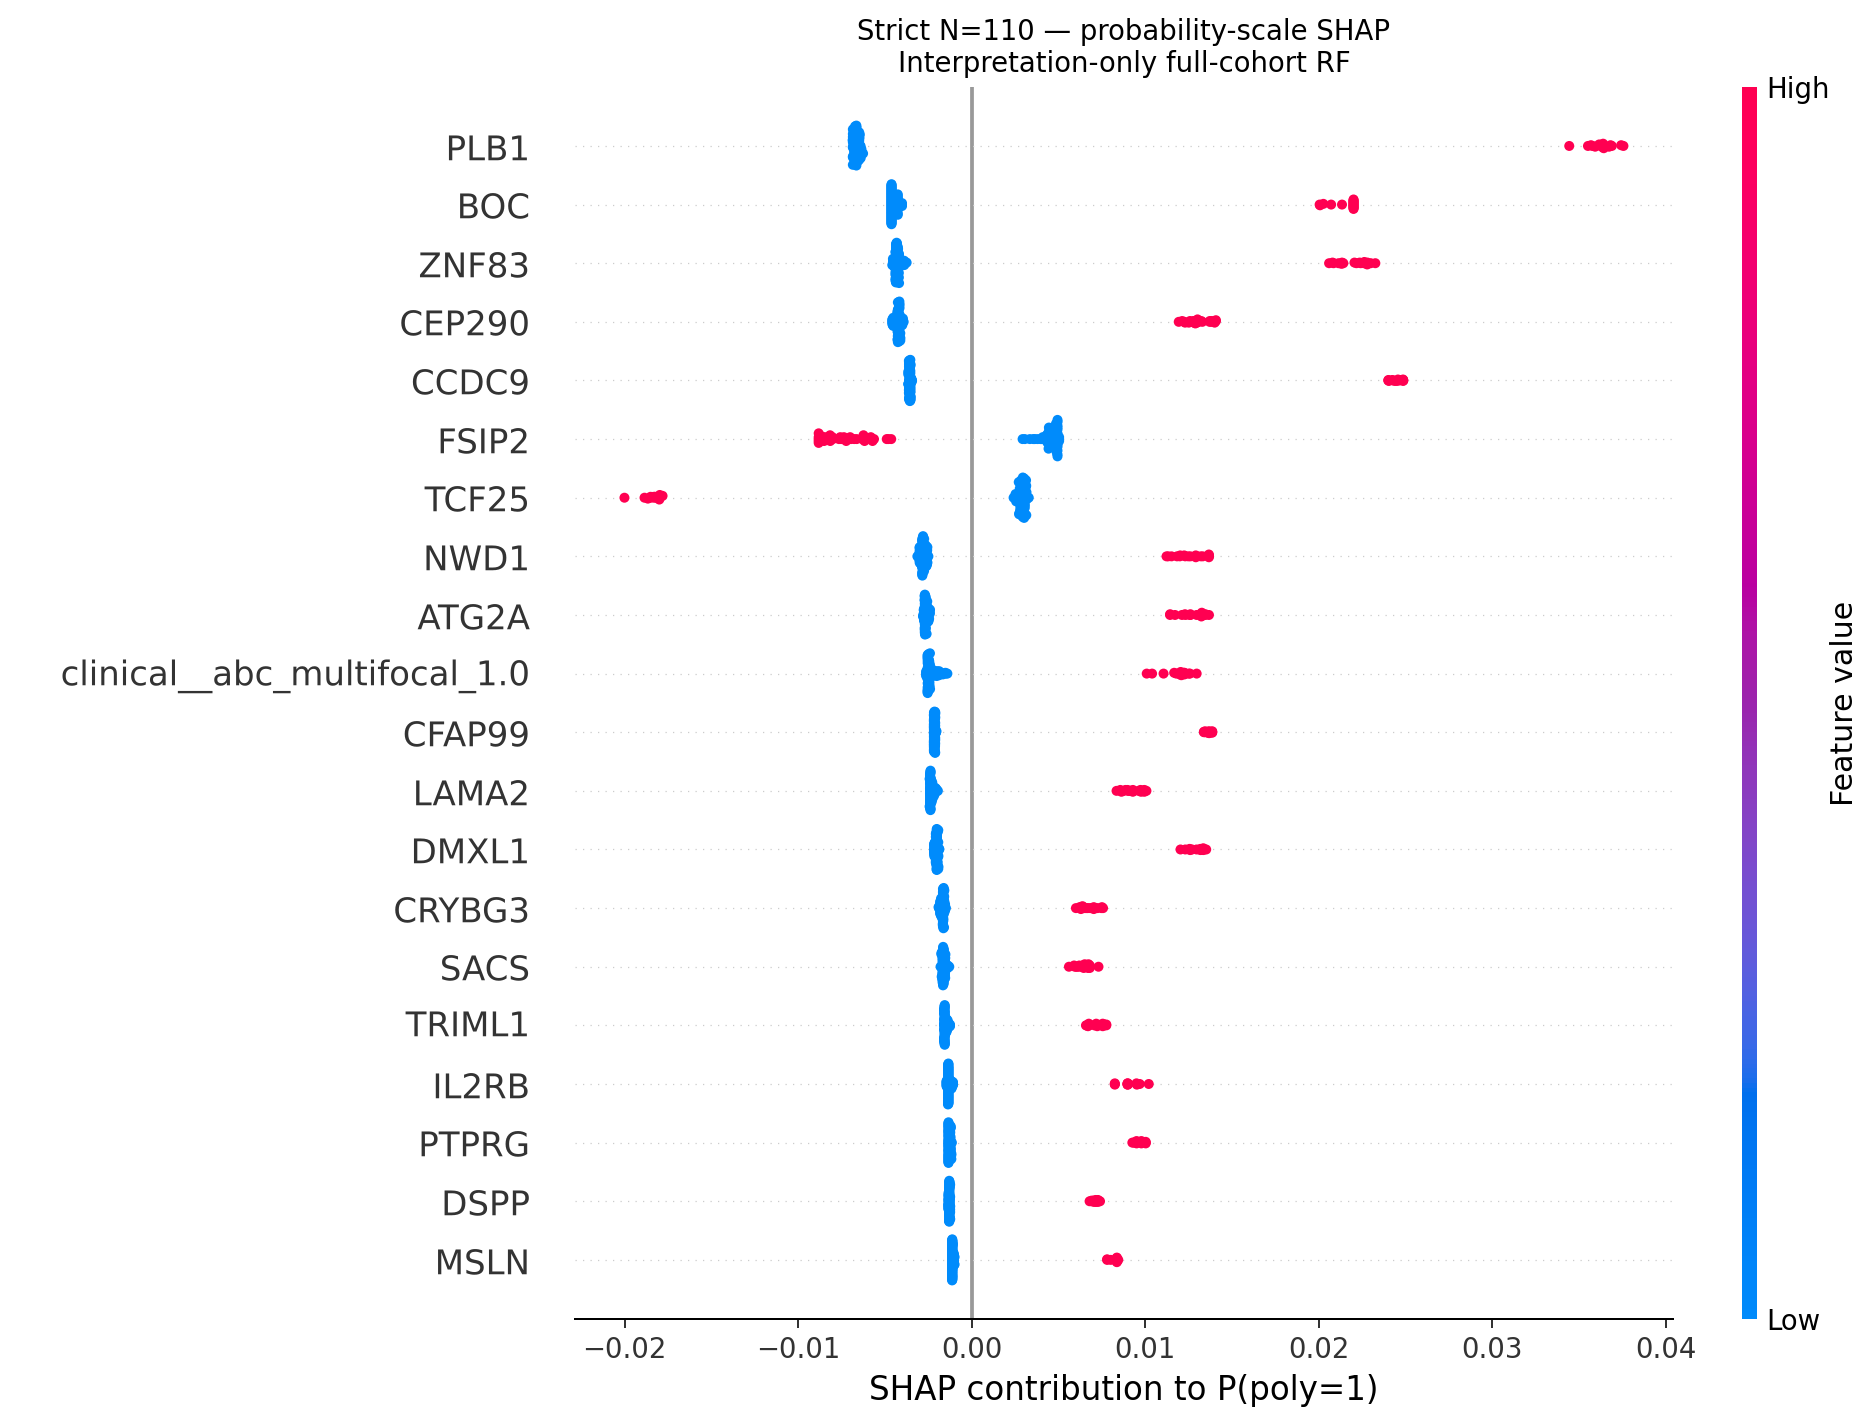

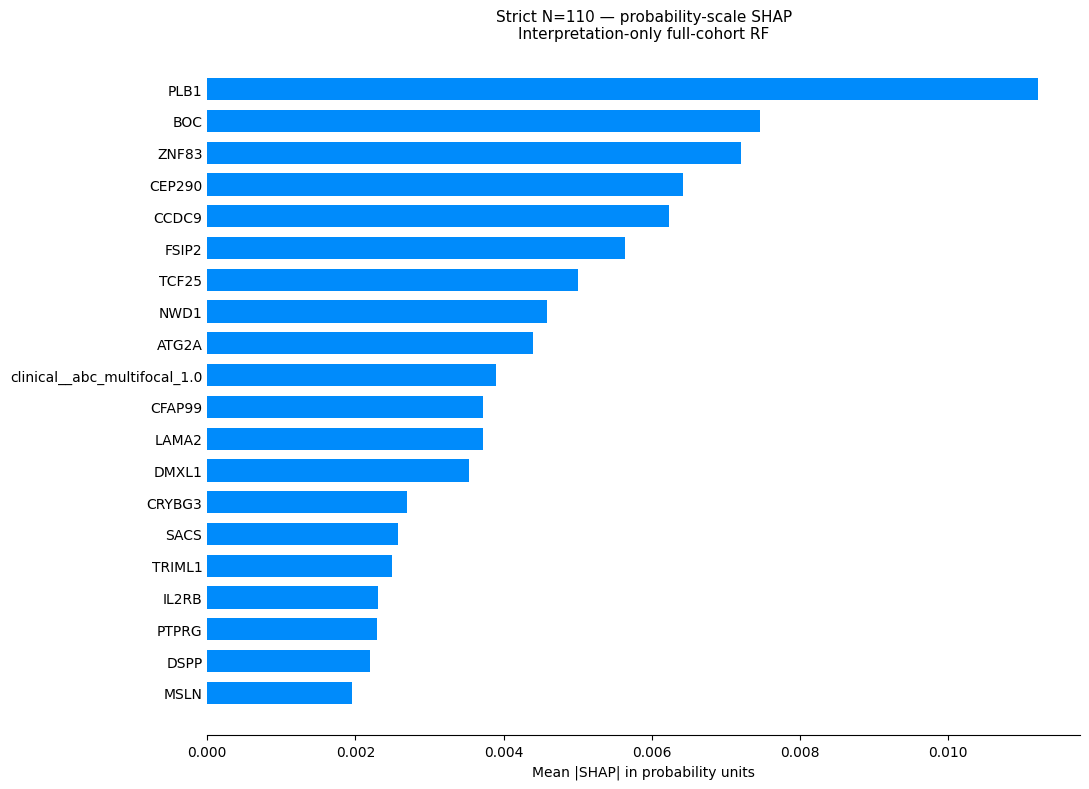

,feature_position,feature,modality,original_clinical_variable,encoded_level,native_impurity_importance,native_rank
0,180,PLB1,mutation,NaN,NaN,0.0740,1
1,102,ZNF83,mutation,NaN,NaN,0.0654,2
2,147,CEP290,mutation,NaN,NaN,0.0613,3
3,71,BOC,mutation,NaN,NaN,0.0565,4
4,165,CCDC9,mutation,NaN,NaN,0.0514,5
5,140,FSIP2,mutation,NaN,NaN,0.0441,6
6,35,ATG2A,mutation,NaN,NaN,0.0440,7
7,137,NWD1,mutation,NaN,NaN,0.0438,8
8,142,LAMA2,mutation,NaN,NaN,0.0368,9
9,149,CFAP99,mutation,NaN,NaN,0.0359,10


,model_output,positive_class,positive_class_index,feature_perturbation,background_N,RF_output_shape,positive_class_SHAP_shape,base_value,max_absolute_additivity_error,mean_absolute_additivity_error,absolute_tolerance,feature_names_order_validated,background_subsampled
0,P(poly=1),1,1,interventional,110,"[110, 200, 2]","[110, 200]",0.505,5.66e-9,1.16e-9,1.00e-6,True,False


In [9]:
display_multimodal_interpretation(pd.read_csv(clinical_mutation_dir / 'shap_ranking.csv')[['rank','display_name','feature','modality','mean_abs_shap','mean_signed_shap']].head(20))
display_multimodal_interpretation(symbol_only_saved_plot(clinical_mutation_dir / 'shap_beeswarm.png'))
plot_saved_shap_bar(clinical_mutation_dir / 'shap_ranking.csv')
plt.show()
display_multimodal_interpretation(pd.read_csv(clinical_mutation_dir / 'native_importance.csv').head(20))
display_multimodal_interpretation(pd.DataFrame([json.loads((clinical_mutation_dir / 'shap_agreement.json').read_text())]))

## Three-modality Random Forest

Clinical, mutation and gene-level TPM inputs are preprocessed within each training partition before combined feature selection. Final input membership and attribution are distinct from outer-fold recurrence.

The full-cohort fit completed, but probability-scale TreeSHAP failed its numerical additivity check (maximum absolute residual 0.005996, tolerance 0.000001). SHAP rankings and modality attribution are therefore withheld. The table below reports native, unsigned impurity importance only; it is not SHAP. No alternative attribution scale is substituted.

The failure was localized to threshold precision in SHAP 0.52's interventional tree implementation: a float64 split threshold in tree 92 is rounded to float32, changing the branch for one of 110 patients. With the full 110-row classifier-input background, exact interventional TreeExplainer (`model_output="probability"`, `approximate=False`) gives a median absolute residual of 2.29×10⁻⁹, a 95th percentile of 5.75×10⁻⁹ and a maximum of 0.005996; one patient exceeds each threshold from 10⁻⁶ to 10⁻³.

Class ordering, input order and pipeline probabilities agree. Float64 inputs, consistently float32 inputs and a deterministic 28-row diagnostic background do not resolve the failure. Raw interventional SHAP also fails. Raw tree-path-dependent SHAP passes (maximum residual 8.88×10⁻¹⁶), but uses a different attribution assumption and is not substituted. Probability-scale SHAP remains unpublished. The fitted model and validation tolerance are unchanged.

The precision mechanism is consistent with the float threshold used in the [SHAP 0.52 interventional implementation](https://github.com/shap/shap/blob/v0.52.0/shap/cext/tree_shap.h#L665-L669).


In [2]:
clinical_mutation_transcriptomics_dir = OUTPUT / 'clinical_mutation_transcriptomics'
thesis_display(pd.DataFrame([json.loads((clinical_mutation_transcriptomics_dir / 'best_params.json').read_text())]))
thesis_display(pd.read_csv(clinical_mutation_transcriptomics_dir / 'classifier_input_features.csv').groupby('modality').size().rename('Classifier inputs').to_frame())

,configuration,family,best_params,best_inner_macro_f1,interpretation_only,N,n_splits,scoring,random_state,n_retained_before_selection,n_classifier_inputs,candidate_count
0,clinical_mutation_transcriptomics,random_forest,"{'classifier__class_weight': 'balanced', 'clas...",0.680,True,110,5,f1_macro,42,22697,200,96


,Classifier inputs
modality,
clinical,1
mutation,41
transcriptomics,158


In [3]:
display_multimodal_interpretation(pd.read_csv(clinical_mutation_transcriptomics_dir / 'native_importance.csv').head(20))
display_multimodal_interpretation(pd.DataFrame([json.loads((clinical_mutation_transcriptomics_dir / 'shap_agreement.json').read_text())]))

,feature_position,feature,modality,original_clinical_variable,encoded_level,native_impurity_importance,native_rank
0,178,H3C14,transcriptomics,NaN,NaN,0.0952,1
1,165,KNTC1,transcriptomics,NaN,NaN,0.0604,2
2,195,SLC5A8,transcriptomics,NaN,NaN,0.0586,3
3,90,ZNF549,transcriptomics,NaN,NaN,0.0452,4
4,135,ACSL6,transcriptomics,NaN,NaN,0.0438,5
5,163,KIAA2012,transcriptomics,NaN,NaN,0.0307,6
6,40,MUC4,mutation,NaN,NaN,0.0287,7
7,180,PRAMEF14,transcriptomics,NaN,NaN,0.0255,8
8,54,ACHE,transcriptomics,NaN,NaN,0.0246,9
9,107,MCTP2,transcriptomics,NaN,NaN,0.0233,10


,status,fit_complete,SHAP_validated,model_output,background_N,max_absolute_additivity_error,mean_absolute_additivity_error,absolute_tolerance,RF_output_shape,positive_class_SHAP_shape,positive_class,source_error,no_SHAP_values_or_rankings_published,no_scale_switch
0,blocked_probability_SHAP_additivity,True,False,P(poly=1),110,0.006,5.50e-5,1.00e-6,"[110, 200, 2]","[110, 200]",1,Probability-scale additivity failed: {'model_o...,True,True


## Limitations

All interpretation models use the full 110 patients after interpretation-only tuning. Their search and training results are not unbiased generalisation estimates; the locked outer nested-CV evaluation remains the predictive evidence. SHAP describes fitted behavior, not causality. Correlated features, one-hot encoding and modality feature counts affect attribution. Clinical coefficients are regularized predictive parameters without inferential confidence intervals. Biological gene sets remain selected with respect to the oligo/poly phenotype, and no membership is changed in response to these interpretations.

The strongest transcriptomic RF attributions are SLC5A8 and H3C14; PLB1 ranks highly in both mutation models. These patterns are exploratory model-specific findings. Three-modality interpretation is limited to input membership and native importance because probability-scale SHAP failed additivity validation.

## Cross-fold feature importance for clinical, mutation and clinical+mutation models

This post-hoc visualisation summarises the selected clinical L2 logistic regression, mutation Random Forest and clinical+mutation Random Forest across the same five frozen outer folds of the common cohort (N=110). It is separate from the full-cohort interpretation refits above. No fitting cells are required.

The source contains values from **prediction-validated reconstructed outer-fold models**. Exact agreement with preserved held-out predictions does not prove identical historical coefficients or trees. No model is fitted here.

For each configuration, feature identities are unioned across folds, with zero assigned when a feature did not reach a fold's classifier. Clinical values are absolute standardized coefficients; RF values are native impurity-based `feature_importances_`, not split-use frequencies. Ranking uses the arithmetic mean across five folds, with sample SD (`ddof=1`) as error bars. Each panel shows exactly ten features. Encoded clinical categories without verified readable mappings retain their original labels. Symmetric SD bars may extend below zero; they are not confidence intervals or negative fold importances.

The interpretation tables are computed from the saved reconstruction outputs, and the reconstruction is checked against the saved checkpoint feature lists and the prediction-validation records before plotting. PNG/PDF exports are saved in `figures/results/common_cohort/`; the figures also render natively below. The reconstruction outputs are read-only inputs and are never overwritten.


In [ ]:
S = Path(
    '/mnt/data3/MCPP-Breast/Machine-Learning-Models-poly_vs_oligo/'
    'Common-Cohort-Modality-Comparison/reconstruction'
)
O = ROOT / 'figures/results/common_cohort'
mapping = gene_symbols()
d = pd.read_csv(S / 'coefficients_and_native_importances.csv')
tables = {}
for cfg, fam in [('clinical', 'logreg_l2'), ('mutation', 'random_forest'), ('clinical_mutation', 'random_forest')]:
    g = d[(d.configuration == cfg) & (d.family == fam)].copy()
    col = 'coefficient' if fam == 'logreg_l2' else 'native_importance'
    m = g.pivot(index='feature_name', columns='outer_fold', values=col).reindex(columns=range(1, 6)).fillna(0)
    if fam == 'logreg_l2':
        m = m.abs()
    t = m.rename(columns={f: f'fold_{f}_value' for f in range(1, 6)}).reset_index()
    t['modality'] = t.feature_name.str.split('__').str[0]

    def label(n):
        mod, ident = n.split('__', 1)
        if mod == 'mutation':
            return mapping.get(ident, ident)
        return {'abc_ajcc_x_n_N0': 'AJCC N0'}.get(ident, ident)

    t['feature'] = t.feature_name.map(label)
    t['mean_abs_coefficient_or_importance'] = m.mean(axis=1).to_numpy()
    t['sample_sd'] = m.std(axis=1, ddof=1).to_numpy()
    t = t.sort_values(
        ['mean_abs_coefficient_or_importance', 'feature_name'],
        ascending=[False, True],
    ).reset_index(drop=True)
    t['rank'] = np.arange(1, len(t) + 1)
    t = t[
        [
            'feature',
            'feature_name',
            'modality',
            *[f'fold_{f}_value' for f in range(1, 6)],
            'mean_abs_coefficient_or_importance',
            'sample_sd',
            'rank',
        ]
    ]
    tables[cfg] = t

Verified: all three top-10 lists and all five-fold values, means and sample SDs exactly match the audited CSVs.


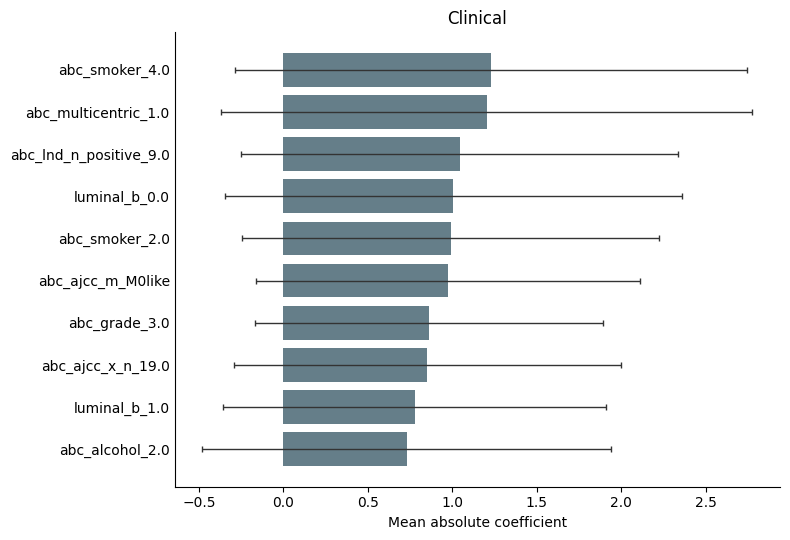

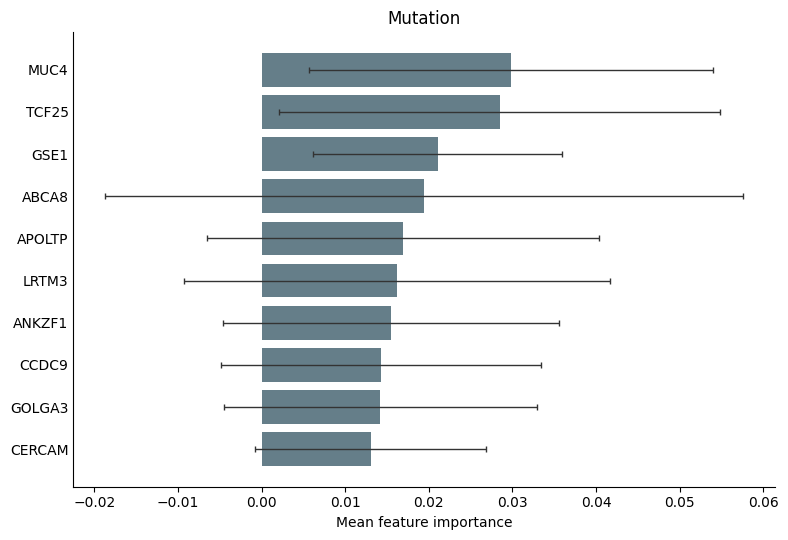

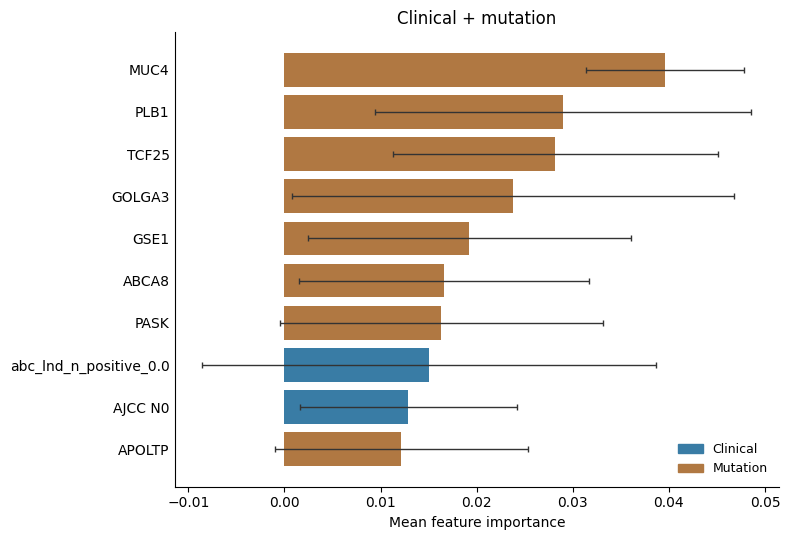

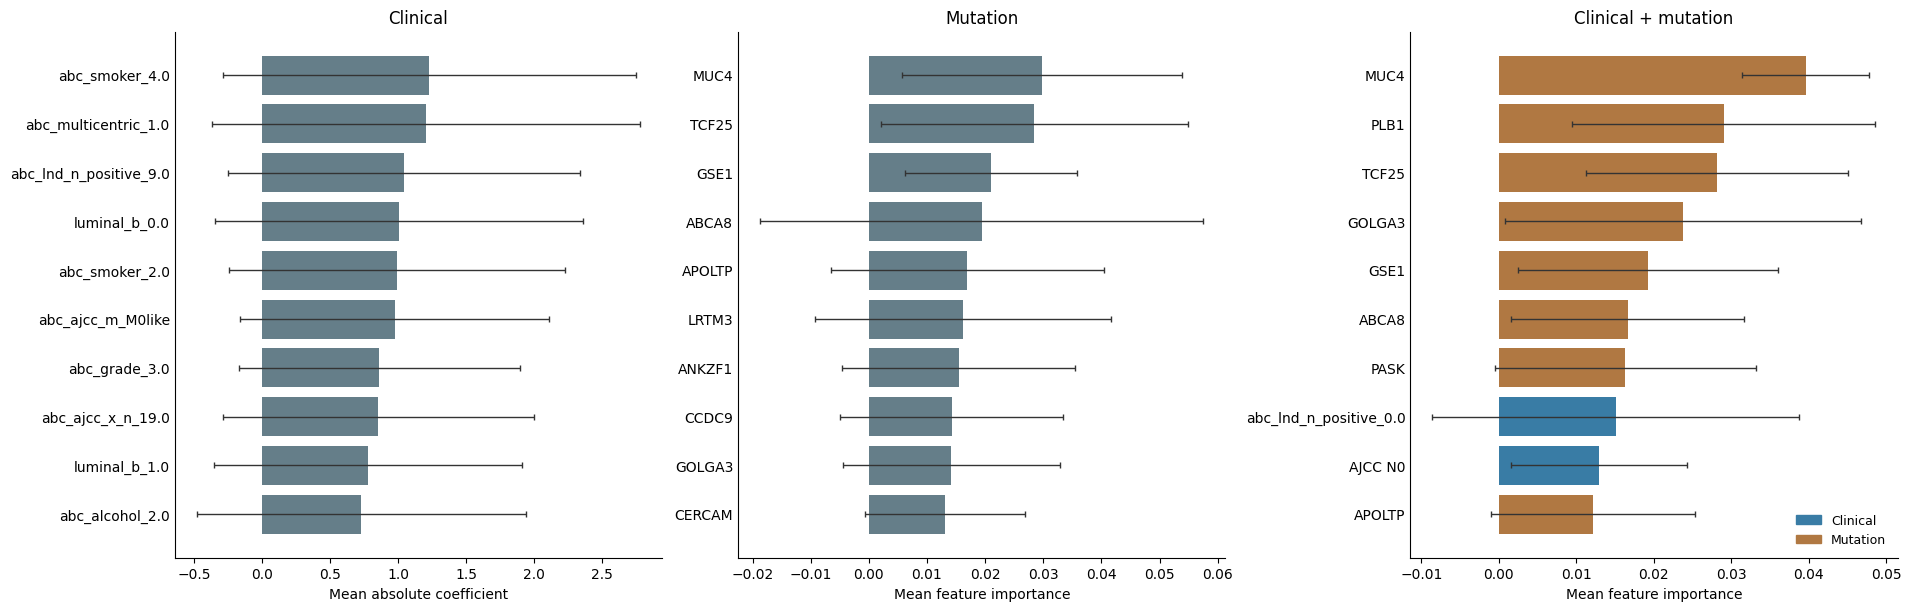

In [2]:
O.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10})
colors={'clinical':'#397ca5','mutation':'#b07842'}
def panel(ax,cfg,title):
 t=tables[cfg].head(10); y=np.arange(10)
 ax.barh(y,t.mean_abs_coefficient_or_importance,xerr=t.sample_sd,color=[colors[m] for m in t.modality] if cfg=='clinical_mutation' else '#657e89',capsize=2,error_kw={'elinewidth':1,'ecolor':'#333333'})
 ax.set(yticks=y,yticklabels=t.feature,xlabel='Mean absolute coefficient' if cfg=='clinical' else 'Mean feature importance',title=title)
 ax.invert_yaxis();ax.spines[['top','right']].set_visible(False);ax.tick_params(axis='y',length=0)
 if cfg=='clinical_mutation':ax.legend(handles=[Patch(color=colors[m],label=m.title()) for m in ['clinical','mutation']],frameon=False,fontsize=9,loc='lower right')
for cfg,title in [('clinical','Clinical'),('mutation','Mutation'),('clinical_mutation','Clinical + mutation')]:
 fig,ax=plt.subplots(figsize=(8,5.5));panel(ax,cfg,title);fig.tight_layout()
 for ext in ['png','pdf']:fig.savefig(O/f'{cfg}_common_cohort_top10_feature_importance.{ext}',dpi=350,bbox_inches='tight')
 plt.show()
fig,axs=plt.subplots(1,3,figsize=(19,6),layout='constrained')
for ax,cfg,title in zip(axs,tables,['Clinical','Mutation','Clinical + mutation']):panel(ax,cfg,title)
for ext in ['png','pdf']:fig.savefig(O/f'model_interpretation_clinical_mutation_three_panel.{ext}',dpi=350,bbox_inches='tight')
plt.show()
